In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Load the cleaned datasets
clients = pd.read_csv("clients_cleaned.csv")
properties = pd.read_csv("properties_cleaned.csv")

print("Clients shape:", clients.shape)
print("Properties shape:", properties.shape)

display(clients.head())
display(properties.head())

Clients shape: (2000, 12)
Properties shape: (10000, 9)


,client_id,client_type,first_name,last_name,date_of_birth,gender,country,region,acquisition_purpose,satisfaction_score,loan_applied,referral_channel
0,C0001,Individual,Kareem,Liu,1968-05-11,F,USA,California,Home,4,Yes,Website
1,C0002,Individual,Trystan,Oconnor,1962-11-26,M,USA,California,Home,1,No,Website
2,C0003,Individual,Kale,Gay,1959-04-07,M,USA,California,Home,4,Yes,Agency
3,C0004,Individual,Russell,Gross,1959-11-25,M,USA,California,Home,5,No,Website
4,C0005,Company,Marleez,Co,1976-02-28,M,USA,California,Investment,5,No,Website


,listing_id,tower_number,transaction_date,unit_category,unit_number,floor_area_sqft,sale_price,listing_status,client_ref
0,1012,1,2024-01-01,Apartment,12,1160.36,300385.62,Sold,C0027
1,1015,1,2024-01-01,Apartment,15,782.25,208930.81,Sold,C0097
2,1021,1,2024-01-01,Apartment,21,756.21,218585.92,Sold,C0113
3,1030,1,2024-01-01,Apartment,30,743.09,246172.68,Sold,C0141
4,2016,2,2024-01-01,Apartment,16,701.66,212265.67,Sold,C0146


In [3]:
# Statistical summary
print("CLIENT DATA SUMMARY")
display(clients.describe(include="all").T)

print("PROPERTY DATA SUMMARY")
display(properties.describe(include="all").T)

CLIENT DATA SUMMARY


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
client_id,2000,2000,C1984,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
client_type,2000,2,Individual,1897,NaN,NaN,NaN,NaN,NaN,NaN,NaN
first_name,2000,337,Carl,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
last_name,2000,224,Co,103,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_of_birth,2000,1889,1967-04-13,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,2000,2,M,1012,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,2000,10,USA,1538,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,2000,57,California,633,NaN,NaN,NaN,NaN,NaN,NaN,NaN
acquisition_purpose,2000,2,Home,1385,NaN,NaN,NaN,NaN,NaN,NaN,NaN
satisfaction_score,2000.0,NaN,NaN,NaN,3.029,1.413562,1.0,2.0,3.0,4.0,5.0


PROPERTY DATA SUMMARY


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
listing_id,10000.0,NaN,NaN,NaN,105898.2774,74414.566199,1002.0,50389.75,100404.5,150411.25,990026.0
tower_number,10000.0,NaN,NaN,NaN,10.3701,5.769025,1.0,5.0,10.0,15.0,20.0
transaction_date,10000,24,2024-01-06,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN
unit_category,10000,2,Apartment,8547,NaN,NaN,NaN,NaN,NaN,NaN,NaN
unit_number,10000.0,NaN,NaN,NaN,28.9992,16.88242,1.0,15.0,29.0,43.0,70.0
floor_area_sqft,10000.0,NaN,NaN,NaN,1139.941412,418.373967,410.71,782.2,1110.88,1499.0,1957.16
sale_price,10000.0,NaN,NaN,NaN,344374.678683,131563.099417,97402.8,232173.6425,330680.845,448852.575,736652.27
listing_status,10000,2,Sold,7305,NaN,NaN,NaN,NaN,NaN,NaN,NaN
client_ref,7305,2000,C0005,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# Missing values and data quality
print("CLIENT MISSING VALUES")
display(clients.isnull().sum())

print("PROPERTY MISSING VALUES")
display(properties.isnull().sum())

print("Duplicate client records:", clients.duplicated().sum())
print("Duplicate property records:", properties.duplicated().sum())


CLIENT MISSING VALUES


,0
client_id,0
client_type,0
first_name,0
last_name,0
date_of_birth,0
gender,0
country,0
region,0
acquisition_purpose,0
satisfaction_score,0


PROPERTY MISSING VALUES


,0
listing_id,0
tower_number,0
transaction_date,0
unit_category,0
unit_number,0
floor_area_sqft,0
sale_price,0
listing_status,0
client_ref,2695


Duplicate client records: 0
Duplicate property records: 0



Distribution of client_type


,Count
client_type,
Individual,1897
Company,103


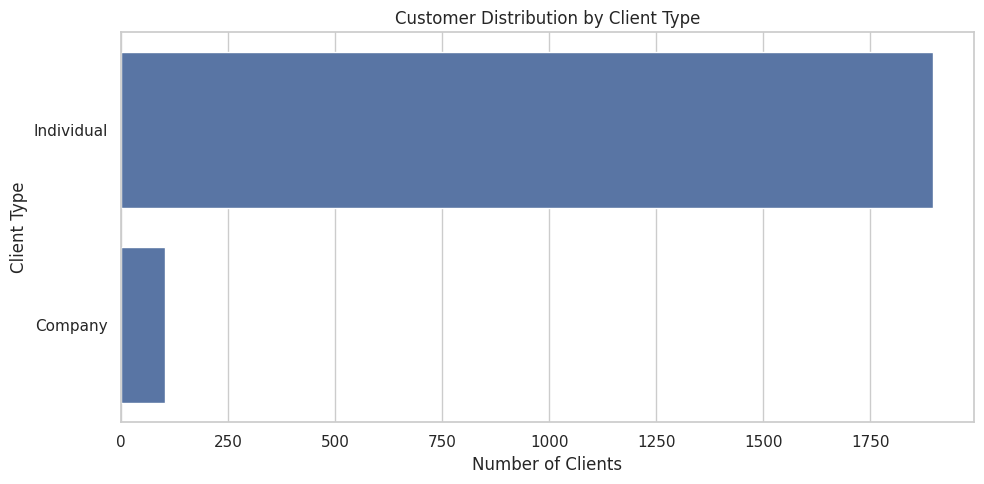


Distribution of gender


,Count
gender,
M,1012
F,988


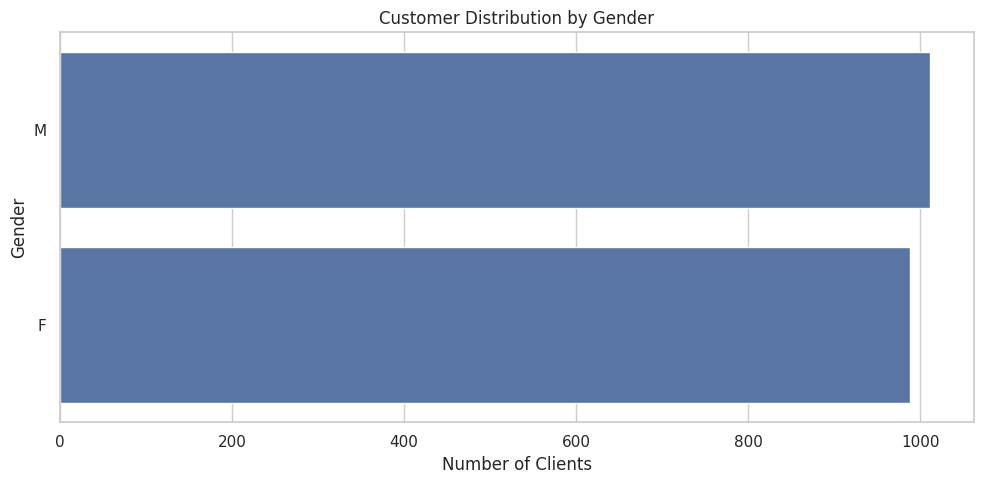


Distribution of country


,Count
country,
USA,1538
UK,95
Canada,85
Germany,56
France,53
Belgium,43
Mexico,40
Australia,39
Russia,36


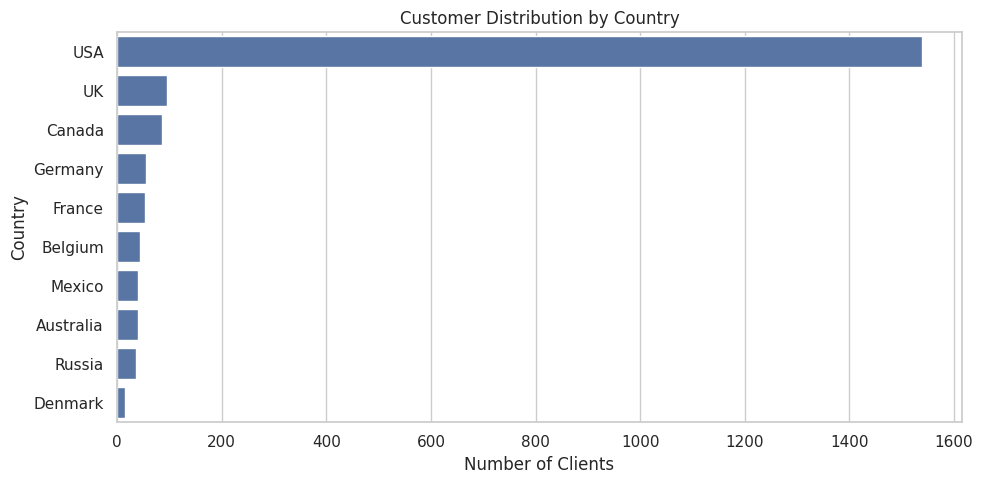


Distribution of region


,Count
region,
California,633
Nevada,143
Colorado,118
Arizona,108
Oregon,96
Utah,87
Washington,73
Virginia,65
Texas,56


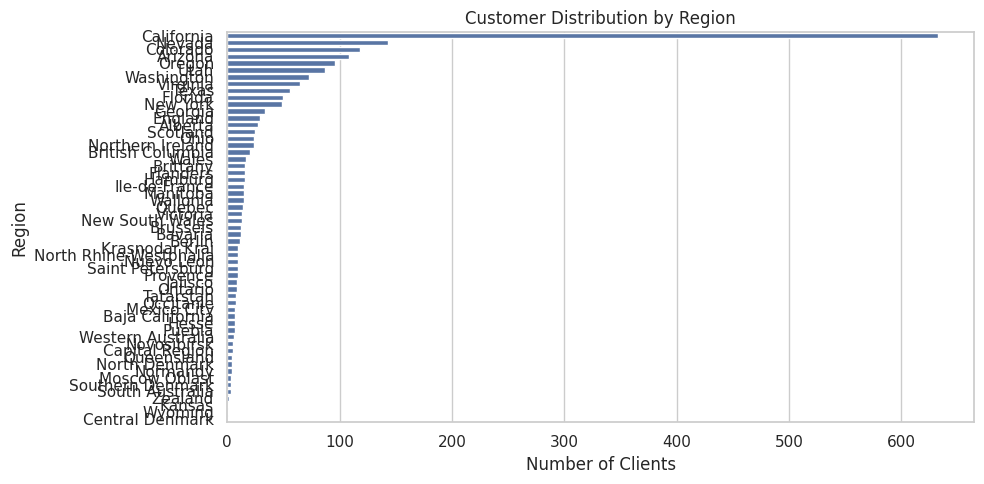

In [5]:
# Customer demographics
demographic_columns = [
    "client_type",
    "gender",
    "country",
    "region"
]

for col in demographic_columns:
    print(f"\nDistribution of {col}")
    display(clients[col].value_counts(dropna=False).to_frame("Count"))

    plt.figure(figsize=(10, 5))
    sns.countplot(
        data=clients,
        y=col,
        order=clients[col].value_counts().index
    )
    plt.title(f"Customer Distribution by {col.replace('_', ' ').title()}")
    plt.xlabel("Number of Clients")
    plt.ylabel(col.replace("_", " ").title())
    plt.tight_layout()
    plt.show()

,Number of Clients
acquisition_purpose,
Home,1385
Investment,615


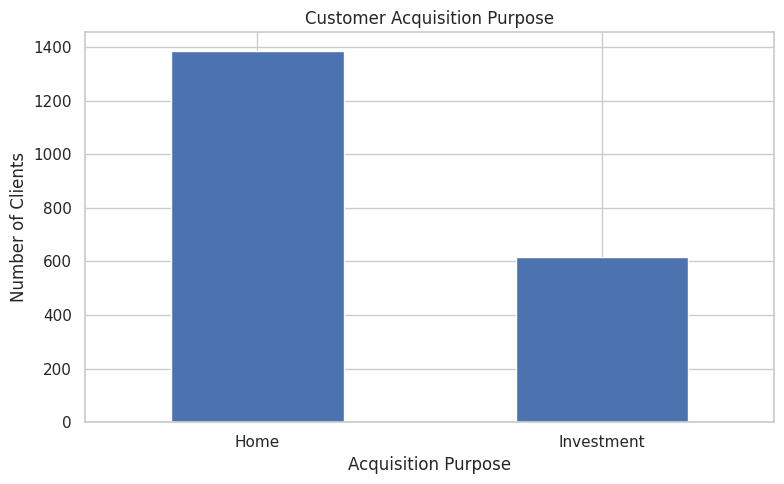

In [6]:
# Customer acquisition purpose
purpose_counts = clients["acquisition_purpose"].value_counts()

display(purpose_counts.to_frame("Number of Clients"))

purpose_counts.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

plt.title("Customer Acquisition Purpose")
plt.xlabel("Acquisition Purpose")
plt.ylabel("Number of Clients")
plt.tight_layout()
plt.show()

,Number of Clients
loan_applied,
No,1264
Yes,736


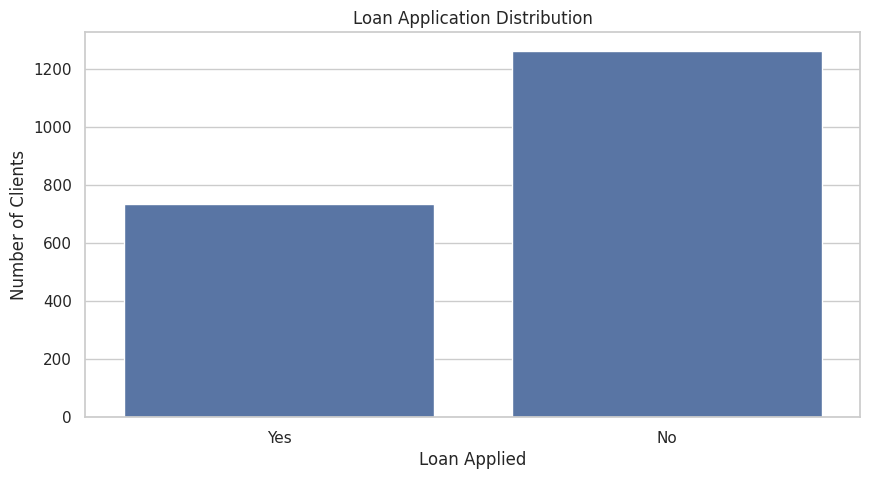

In [7]:
# Loan application analysis
loan_counts = clients["loan_applied"].value_counts()

display(loan_counts.to_frame("Number of Clients"))

sns.countplot(data=clients, x="loan_applied")
plt.title("Loan Application Distribution")
plt.xlabel("Loan Applied")
plt.ylabel("Number of Clients")
plt.show()

loan_applied,No,Yes
acquisition_purpose,,
Home,883,502
Investment,381,234


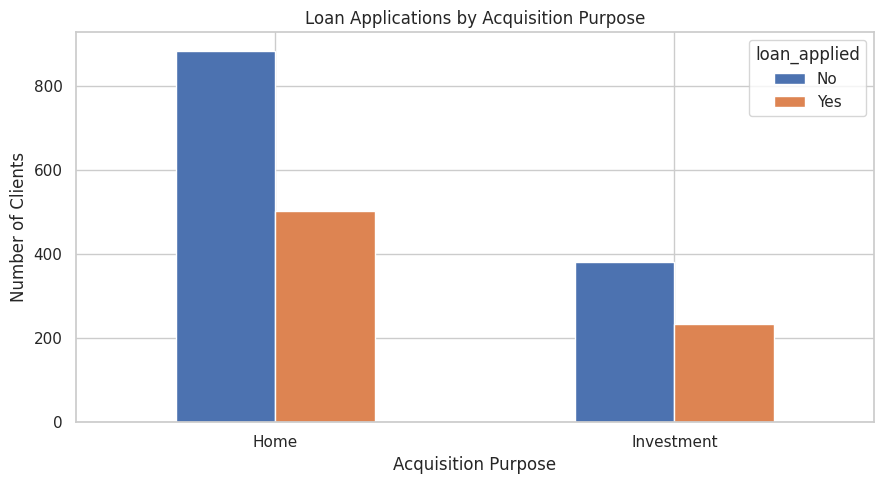

In [8]:
# Now compare loan behavior by acquisition purpose.
loan_purpose = pd.crosstab(
    clients["acquisition_purpose"],
    clients["loan_applied"]
)

display(loan_purpose)

loan_purpose.plot(kind="bar", figsize=(9, 5))
plt.title("Loan Applications by Acquisition Purpose")
plt.xlabel("Acquisition Purpose")
plt.ylabel("Number of Clients")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Satisfaction score distribution


,count
satisfaction_score,
1,395
2,379
3,404
4,417
5,405



Average satisfaction by client type


,count,mean,median
client_type,,,
Company,103,3.067961,3.0
Individual,1897,3.026885,3.0


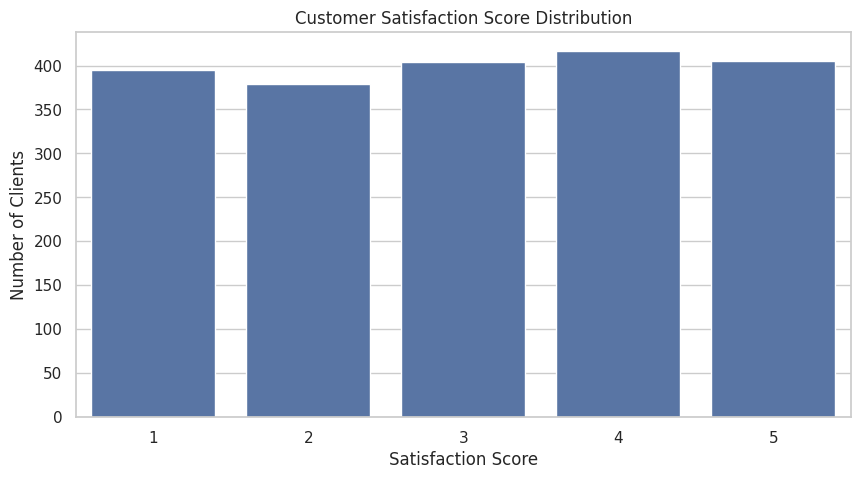

In [9]:
# Customer satisfaction analysis
print("Satisfaction score distribution")
display(clients["satisfaction_score"].value_counts().sort_index())

print("\nAverage satisfaction by client type")
display(
    clients.groupby("client_type")["satisfaction_score"]
    .agg(["count", "mean", "median"])
)

sns.countplot(data=clients, x="satisfaction_score")
plt.title("Customer Satisfaction Score Distribution")
plt.xlabel("Satisfaction Score")
plt.ylabel("Number of Clients")
plt.show()

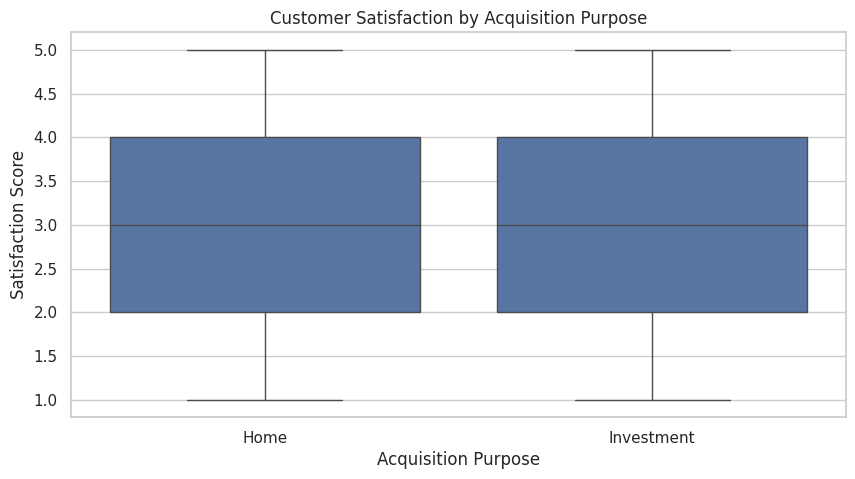

In [10]:
# You can also examine satisfaction by purchase purpose:
sns.boxplot(
    data=clients,
    x="acquisition_purpose",
    y="satisfaction_score"
)

plt.title("Customer Satisfaction by Acquisition Purpose")
plt.xlabel("Acquisition Purpose")
plt.ylabel("Satisfaction Score")
plt.show()

,age
count,2000.000000
mean,54.100500
std,17.343581
min,24.000000
25%,39.000000
50%,55.000000
75%,69.000000
max,93.000000


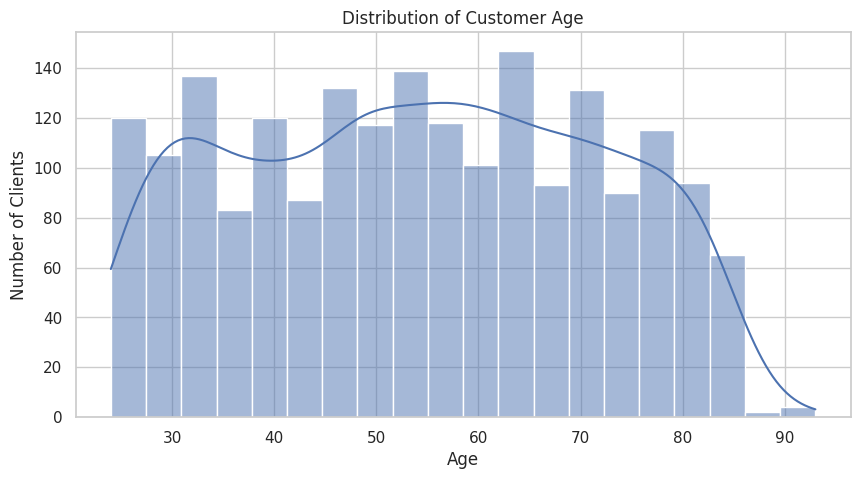

In [11]:
# Customer age analysis
clients["date_of_birth"] = pd.to_datetime(
    clients["date_of_birth"],
    errors="coerce"
)

reference_date = pd.Timestamp("2025-01-01")

clients["age"] = (
    reference_date.year
    - clients["date_of_birth"].dt.year
    - (
        (clients["date_of_birth"].dt.month > reference_date.month)
        | (
            (clients["date_of_birth"].dt.month == reference_date.month)
            & (clients["date_of_birth"].dt.day > reference_date.day)
        )
    ).astype(int)
)

display(clients["age"].describe())

sns.histplot(data=clients, x="age", bins=20, kde=True)
plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Number of Clients")
plt.show()

,Property Count
listing_status,
Sold,7305
Available,2695


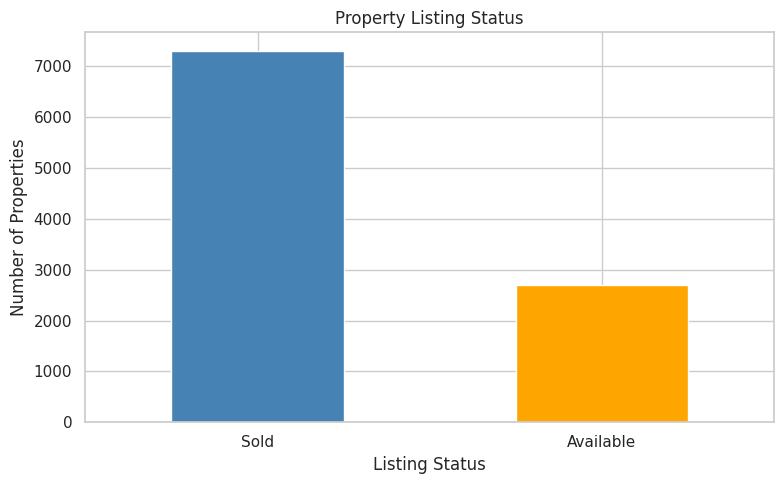

In [12]:
# Property listing status
status_counts = properties["listing_status"].value_counts()

display(status_counts.to_frame("Property Count"))

status_counts.plot(
    kind="bar",
    color=["steelblue", "orange"],
    figsize=(8, 5),
    rot=0
)

plt.title("Property Listing Status")
plt.xlabel("Listing Status")
plt.ylabel("Number of Properties")
plt.tight_layout()
plt.show()


In [13]:
# Property price analysis
print("Property sale price summary")
display(properties["sale_price"].describe())

print("Floor area summary")
display(properties["floor_area_sqft"].describe())

Property sale price summary


,sale_price
count,10000.000000
mean,344374.678683
std,131563.099417
min,97402.800000
25%,232173.642500
50%,330680.845000
75%,448852.575000
max,736652.270000


Floor area summary


,floor_area_sqft
count,10000.000000
mean,1139.941412
std,418.373967
min,410.710000
25%,782.200000
50%,1110.880000
75%,1499.000000
max,1957.160000


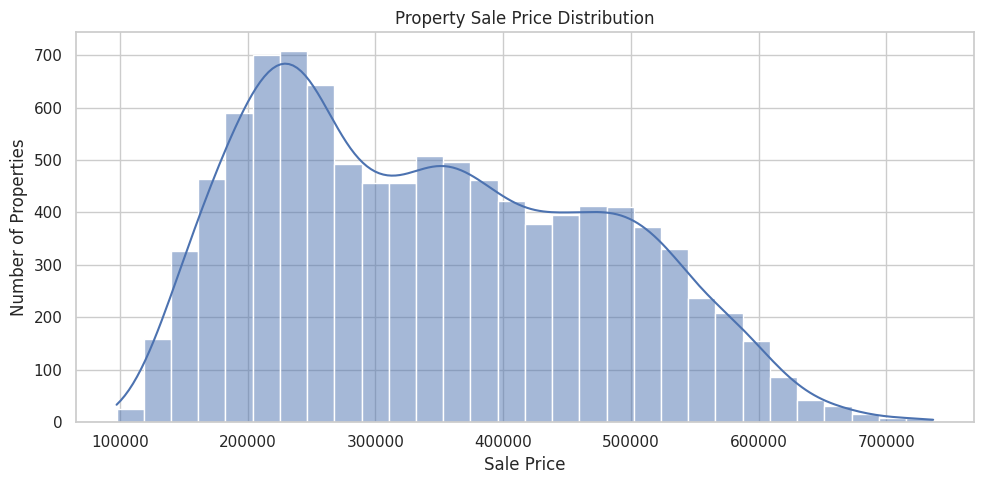

In [14]:
# Visualize the sale price distribution:
sns.histplot(
    data=properties,
    x="sale_price",
    bins=30,
    kde=True
)

plt.title("Property Sale Price Distribution")
plt.xlabel("Sale Price")
plt.ylabel("Number of Properties")
plt.tight_layout()
plt.show()

Price statistics by unit category


,count,mean,median,min,max
unit_category,,,,,
Apartment,8547,341299.265561,327725.79,97402.80,736652.27
Office,1453,362465.219601,348371.69,102745.33,734390.86


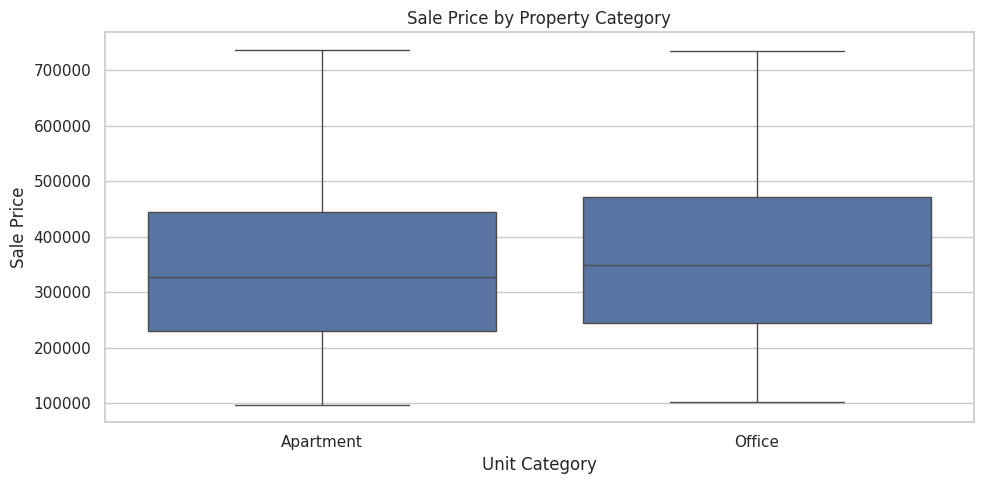

In [15]:
# Property price by category and status
print("Price statistics by unit category")
display(
    properties.groupby("unit_category")["sale_price"]
    .agg(["count", "mean", "median", "min", "max"])
)

sns.boxplot(
    data=properties,
    x="unit_category",
    y="sale_price"
)

plt.title("Sale Price by Property Category")
plt.xlabel("Unit Category")
plt.ylabel("Sale Price")
plt.tight_layout()
plt.show()

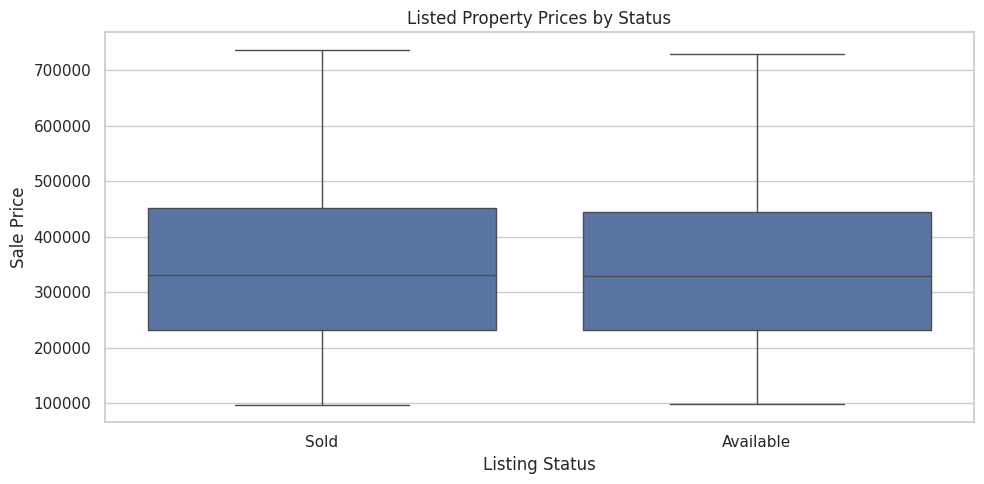

In [16]:
# Compare price distributions for sold and available properties:
sns.boxplot(
    data=properties,
    x="listing_status",
    y="sale_price"
)

plt.title("Listed Property Prices by Status")
plt.xlabel("Listing Status")
plt.ylabel("Sale Price")
plt.tight_layout()
plt.show()

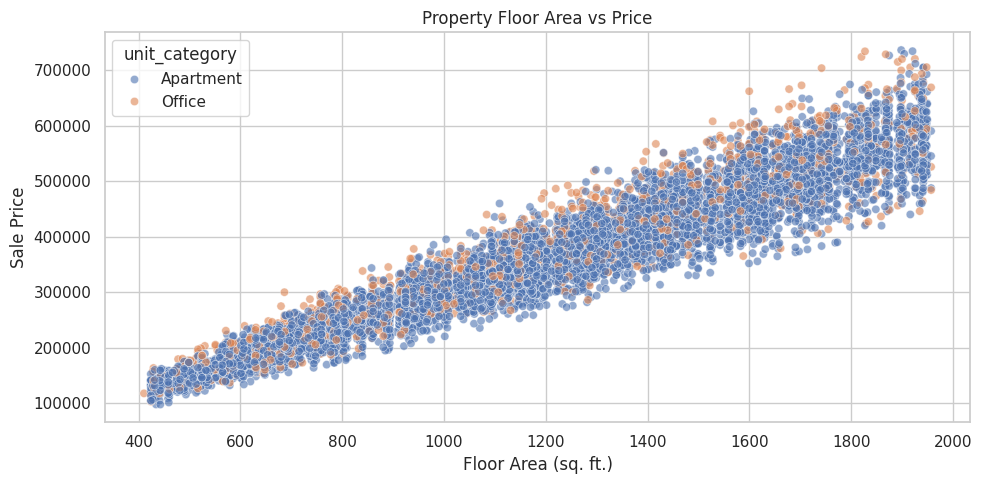

In [17]:
# Analyze property sizes
sns.scatterplot(
    data=properties,
    x="floor_area_sqft",
    y="sale_price",
    hue="unit_category",
    alpha=0.6
)

plt.title("Property Floor Area vs Price")
plt.xlabel("Floor Area (sq. ft.)")
plt.ylabel("Sale Price")
plt.tight_layout()
plt.show()

In [18]:
# Combine clients and properties
print(
    "Sold properties:",
    (properties["listing_status"] == "Sold").sum()
)

print(
    "Available properties:",
    (properties["listing_status"] == "Available").sum()
)

print(
    "Properties with missing client references:",
    properties["client_ref"].isna().sum()
)

Sold properties: 7305
Available properties: 2695
Properties with missing client references: 2695


In [19]:
# Then merge the datasets:
combined = properties.merge(
    clients,
    left_on="client_ref",
    right_on="client_id",
    how="left",
    suffixes=("_property", "_client"),
    indicator=True
)

print("Combined dataset shape:", combined.shape)

display(combined.head())

print("\nMerge status:")
display(combined["_merge"].value_counts())

Combined dataset shape: (10000, 23)


,listing_id,tower_number,transaction_date,unit_category,unit_number,floor_area_sqft,sale_price,listing_status,client_ref,client_id,...,date_of_birth,gender,country,region,acquisition_purpose,satisfaction_score,loan_applied,referral_channel,age,_merge
0,1012,1,2024-01-01,Apartment,12,1160.36,300385.62,Sold,C0027,C0027,...,1968-09-08,M,USA,California,Home,5.0,Yes,Website,56.0,both
1,1015,1,2024-01-01,Apartment,15,782.25,208930.81,Sold,C0097,C0097,...,1943-06-18,M,USA,Virginia,Home,5.0,Yes,Website,81.0,both
2,1021,1,2024-01-01,Apartment,21,756.21,218585.92,Sold,C0113,C0113,...,1949-07-14,M,USA,Utah,Investment,4.0,No,Agency,75.0,both
3,1030,1,2024-01-01,Apartment,30,743.09,246172.68,Sold,C0141,C0141,...,1986-06-21,F,USA,California,Home,5.0,No,Website,38.0,both
4,2016,2,2024-01-01,Apartment,16,701.66,212265.67,Sold,C0146,C0146,...,1963-02-01,M,USA,Colorado,Home,2.0,No,Website,61.0,both



Merge status:


,count
_merge,
both,7305
left_only,2695
right_only,0


In [20]:
# For buyer-specific analysis, use sold listings with matched clients:
buyer_properties = combined[
    (combined["listing_status"] == "Sold")
    & (combined["_merge"] == "both")
].copy()

print("Matched sold property records:", len(buyer_properties))

display(
    buyer_properties.groupby("acquisition_purpose")["sale_price"]
    .agg(["count", "mean", "median"])
)

Matched sold property records: 7305


,count,mean,median
acquisition_purpose,,,
Home,5058,346000.150459,332988.785
Investment,2247,342982.732452,326858.350


,sale_price,floor_area_sqft,satisfaction_score,age
sale_price,1.000000,0.960149,-0.006797,-0.008673
floor_area_sqft,0.960149,1.000000,-0.004819,-0.007672
satisfaction_score,-0.006797,-0.004819,1.000000,0.020886
age,-0.008673,-0.007672,0.020886,1.000000


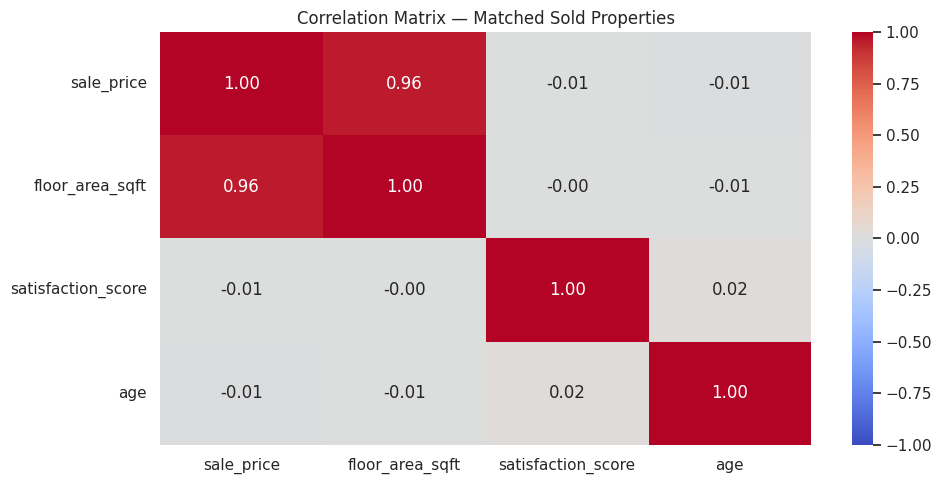

In [21]:
# Correlation analysis
numeric_cols = [
    "sale_price",
    "floor_area_sqft",
    "satisfaction_score",
    "age"
]

corr_data = buyer_properties[numeric_cols].corr(numeric_only=True)

display(corr_data)

sns.heatmap(
    corr_data,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix — Matched Sold Properties")
plt.tight_layout()
plt.show()

In [22]:
# Save your EDA results
combined.to_csv("eda_combined_data.csv", index=False)

clients["client_type"].value_counts().to_csv(
    "eda_client_type_summary.csv"
)

clients["acquisition_purpose"].value_counts().to_csv(
    "eda_acquisition_purpose_summary.csv"
)

properties["listing_status"].value_counts().to_csv(
    "eda_listing_status_summary.csv"
)

print("EDA summary files saved successfully.")

EDA summary files saved successfully.
